#### **Задача**

Провести анализ результатов A/B теста и сделать вывод: запускать новую форму на пользователей или нет

#### **Данные о тесте**

**Кейс:** Тестирование новой формы оплаты ЖКХ с автозаполнением реквизитов

**Гипотеза:** Новая форма с автозаполнением реквизитов увеличит долю успешных оплат ЖКХ

**Воронка оплаты ЖКХ:** 1. Открыл форму оплаты → 2. Ввёл реквизиты → 3. Подтвердил платеж → 4. Успешная оплата

**Ключевая метрика:** конверсия из шага 1 в шаг 4

**Период теста:** 1–30 апреля 2024 (30 дней)

#### **Загрузка данных**

Импорт библиотек

In [43]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

Пользователи `users`

In [66]:
users = pd.read_csv('users.csv', sep=';')
users.head()

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


Платежи `pays`

In [67]:
payments = pd.read_csv('payments.csv', sep=';')
payments.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaN,NaN
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaN,NaN
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaN,NaN
3,5004,1004.0,A,2024-04-09 16:02:00,NaN,NaN,NaN
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


#### **EDA: поиск проблем**

Приведение типов данных

In [86]:
payments['step1_opened'] = pd.to_datetime(payments['step1_opened'])
payments['step2_entered'] = pd.to_datetime(payments['step2_entered'])
payments['step3_confirmed'] = pd.to_datetime(payments['step3_confirmed'])
payments['step4_success'] = pd.to_datetime(payments['step4_success'])


print(payments.dtypes, '\n')
print(users.dtypes)

payment_id                  int64
user_id                   float64
group                      object
step1_opened       datetime64[ns]
step2_entered      datetime64[ns]
step3_confirmed    datetime64[ns]
step4_success      datetime64[ns]
dtype: object 

user_id         int64
group          object
age             int64
city           object
device_type    object
dtype: object


##### **Дубликаты и зависимость**

In [69]:
print('Уникальных user_id в users:', users['user_id'].nunique(), 'из', len(users), '\n')

print('Уникальных payment_id в payments:', payments['payment_id'].nunique(), 'из', len(payments))
print('Уникальных user_id в payments:', payments['user_id'].nunique(), 'из', len(payments))

Уникальных user_id в users: 1504 из 1504 

Уникальных payment_id в payments: 2661 из 2661
Уникальных user_id в payments: 1501 из 2661


In [121]:
print('Группировка пользователей по их количеству payment_id (попыток платежей):')
print(payments.dropna(subset=['user_id']).groupby('user_id').size().value_counts().sort_index())

Группировка пользователей по их количеству payment_id (попыток платежей):
1    740
2    443
3    238
4     80
Name: count, dtype: int64


##### **Пропуски**

In [70]:
payments.isna().sum()

payment_id            0
user_id               1
group                 0
step1_opened          0
step2_entered       405
step3_confirmed     942
step4_success      1139
dtype: int64

In [76]:
print('Платежи с пропущенным user_id:')
display(payments[payments['user_id'].isna()])

Платежи с пропущенным user_id:


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


In [65]:
users.isna().sum()

user_id        0
group          1
age            0
city           1
device_type    0
dtype: int64

In [90]:
print('Пользователи с пропущенной group:')
display(users[users['group'].isna()])

print('Пользователь c user_id=9001 в payments:')
display(payments[payments['user_id'] == 9001])

Пользователи с пропущенной group:


,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios


Пользователь c user_id=9001 в payments:


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success


Пользователя c `user_id=9001` нет в `payments`, откуда можно было бы взять группу (хотя рандомизация происходит на уровне пользователя и `users` источник истины, а не `payments`, мы тем не менее в любом случае не можем её взять), поэтому мы не можем отнести пользователя корректно к конкретной группе, следовательно исключаем как критическую ошибку (хотя он все равно не фигурировал бы в тесте, так как отсутствует в `payments`)

In [91]:
print('Пользователи с пропущенным city:')
display(users[users['city'].isna()])

Пользователи с пропущенным city:


,user_id,group,age,city,device_type
1503,9004,A,30,NaN,android


##### **Аномалии**

In [112]:
print('Пользователи с возрастом вне диапазона 14-90:')
display(users[(users['age'] < 14) | (users['age'] > 90)])

Пользователи с возрастом вне диапазона 14-90:


,user_id,group,age,city,device_type
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios


In [109]:
steps = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
all_dates = pd.concat([payments[col] for col in steps]).dropna()

print(f"Все даты находятся в диапазоне апрель 2024: {(all_dates.min() >= pd.Timestamp('2024-04-01 00:00:00')) and (all_dates.max() <= pd.Timestamp('2024-04-30 23:59:59'))}")

Все даты находятся в диапазоне апрель 2024: True


In [111]:
def has_gap(row):
    flag = False
    for s in steps:
        if pd.isna(row[s]):
            flag = True
        elif flag:
            return True

    for i in range(1, len(steps)):
        prev, curr = steps[i-1], steps[i]
        if not pd.isna(row[prev]) and not pd.isna(row[curr]):
            if row[curr] < row[prev]: 
                return True
    
    return False

err = payments.apply(has_gap, axis=1)

print('Нарушений монотонности воронки (шаг n пустой, а n+1 заполнен или шаг n+1 наступил ранее шага n):', err.sum())


Нарушений монотонности воронки (шаг n пустой, а n+1 заполнен или шаг n+1 наступил ранее шага n): 0


In [160]:
print(users['city'].value_counts(), end='\n\n')
print(users['device_type'].value_counts())

city
Москва    595
Регион    514
СПб       394
Name: count, dtype: int64

device_type
android    777
ios        727
Name: count, dtype: int64


##### **Несогласованность**

Столбцы `user_id` (уникальный идентификатор пользователя, по которому будем объединять данные) и `group`совпадают в двух датасетах (листах). Поэтому необходимо также проверить согласованность данных в `group`

In [127]:
tmp = payments.dropna(subset=['user_id']).copy()
tmp['user_id'] = tmp['user_id'].astype(int)
merged = tmp.merge(users[['user_id', 'group']], on='user_id', suffixes=('_pay', '_user'), how='left')
err_group = merged[merged['group_pay'] != merged['group_user']]
print('Несогласованность group:')
display(err_group[['payment_id', 'user_id', 'group_pay', 'group_user']])

print('Количество payments у этого пользователя: ')
print(len(payments[payments['user_id'] == 1010]))

Несогласованность group:


,payment_id,user_id,group_pay,group_user
2659,99002,1010,B,A


Количество payments у этого пользователя: 
2


#### **Работа с некорректными данными**

| Проблема | Решение |
|---|---|
|дубликатов уникальных идентификаторов нет| — |
|`user_id` в `payments` не уникальны, что влияет на независимость наблюдений|вернемся позднее (выбор метрики)|
|пропуск `user_id` в `payments` не позволяет идентифицировать пользователя, это **критическая** ошибка|исключаем|
|пропуск `group` в `users` не позволяет корректно отнести пользователя к группе, это **критическая** ошибка |исключаем|
|некорректные значения (выбросы) в `age`|\* исключаем|
|пропуск `city` в `users` |\* исключаем|
|несогласованность  `group` у одного пользователя в `users` и `payments` |\* исключаем|
|нарушений диапазона дат и монотонности воронки нет| — |
|случайных ошибок в `city`, `device_type` нет| — |

**\*** данные ошибки не являются критическими, поскольку `age` и `city` не входят в метрику (мы могли бы заменить медианой или просто оставить пустым в основном расчете и исключить из срезов), а истинную `group` взять из `users` (поскольку рандомизация происходит на уровне пользователей), предлагаю **исключить** эти строки как выбросы для чистоты данных, поскольку они составляют менее 0.2%

#### **Удаление выбросов**

In [136]:
payments_clean = payments.dropna(subset=['user_id'])
users_clean = users.dropna(subset=['group'])
users_clean = users_clean[(users_clean['age'] >= 14) & (users_clean['age'] <= 90)]
users_clean = users_clean.dropna(subset=['city'])

# удаляем пользователя с несогласованой группой user_id=1010
payments_clean = payments_clean[payments_clean['user_id'] != 1010]
users_clean = users_clean[users_clean['user_id'] != 1010]

payments_clean = payments_clean[payments_clean['user_id'].isin(users_clean['user_id'])]

print(f"Корректных платежей: {len(payments_clean)}: {dict(users_clean['group'].value_counts())}")
print(f"Корректных пользователей: {len(users_clean)}")

Корректных платежей: 2657: {'B': np.int64(750), 'A': np.int64(749)}
Корректных пользователей: 1499


#### **Выбор метрики (конверсия)**

Как показал EDA выше, у многих пользователей несколько (от 1 до 4) различных платежей за тест. Считать конверсию по каждому платежу **некорректно**, так как один и тот же юзер входит в выборку несколько раз, что нарушает независимость наблюдений

Будем считать **конверсию на уровне пользователя**: если пользователь хотя бы раз успешно оплатил, он считается конвертированным. Также дополнительно посчитаем конверсию по первой попытке для дополнительной проверки

In [223]:
pay_c = payments_clean.merge(
    users_clean[['user_id', 'group', 'age', 'city', 'device_type']],
    on='user_id', how='inner', suffixes=('_pay', '_user')
)
pay_c['success'] = pay_c['step4_success'].notna()


In [141]:
success_by_user = pay_c.groupby('user_id')['success'].max()
users_clean['success'] = users_clean['user_id'].map(success_by_user).fillna(False).astype(bool)

itt = users_clean.groupby('group')['success'].agg(['sum', 'count', 'mean'])
itt.columns = ['successes', 'n', 'conversion']

print('Конверсия')
print(itt)


Конверсия
       successes    n  conversion
group                            
A            492  749    0.656876
B            603  750    0.804000


In [145]:

pay_sorted = pay_c.sort_values(['user_id', 'step1_opened'])
first_attempt = pay_sorted.groupby('user_id').first().reset_index()

fa = first_attempt.groupby('group_user')['success'].agg(['sum', 'count', 'mean'])
fa.columns = ['successes', 'n', 'conversion']
print('Конверсия по первой попытке')
print(fa)


Конверсия по первой попытке
            successes    n  conversion
group_user                            
A                 380  749    0.507343
B                 493  750    0.657333


#### **Проверка на SRM**

С помощью критерия $\chi$-квадрат проверка на соотношение 50%/50% в группах:

In [149]:
chi2_srm, p_srm = stats.chisquare(
    users_clean['group'].value_counts().reindex(['A', 'B']),
    [len(users_clean)/2, len(users_clean)/2]
)

print(f"chi2 = {chi2_srm:.4f}, p-value = {p_srm:.4f}")


chi2 = 0.0007, p-value = 0.9794


**Вывод:** `p-value = 0.98 > 0.05`, значит SRM нет, разбиение корректно

#### **Проверка однородности групп по ключевым признакам**

In [156]:
print('age')
print(users_clean.groupby('group')['age'].agg(['mean', 'std', 'median', 'count']).round(2))
t, p = stats.ttest_ind(users_clean[users_clean.group == 'A']['age'], users_clean[users_clean.group == 'B']['age'])
print(f't-test: t = {t:.3f}, p-value = {p:.4f}')


print('\n')
vu_city = users_clean.dropna(subset=['city'])
ct_city = pd.crosstab(vu_city['group'], vu_city['city'])
print(ct_city)
chi2, p, dof, exp = stats.chi2_contingency(ct_city)
print(f'chi2 = {chi2:.3f}, p-value = {p:.4f}')


print('\n')
ct_dev = pd.crosstab(users_clean['group'], users_clean['device_type'])
print(ct_dev)
chi2, p, dof, exp = stats.chi2_contingency(ct_dev)
print(f'chi2 = {chi2:.3f}, p-value = {p:.4f}')

age
        mean   std  median  count
group                            
A      32.75  7.82    32.0    749
B      32.65  7.78    33.0    750
t-test: t = 0.244, p-value = 0.8072


city   Москва  Регион  СПб
group                     
A         287     268  194
B         306     245  199
chi2 = 1.703, p-value = 0.4268


device_type  android  ios
group                    
A                405  344
B                369  381
chi2 = 3.370, p-value = 0.0664


**Вывод:**
- `city` и `age` хорошо сбалансированы  (`p-value` сильно больше 0.05)
- по `device_type` `p-value` довольно близок к 0.05, это можно отметить как слабое место эксперимента, но тем не менее `p-value = 0.066` больше 0.05, поэтому баланс групп корректен

#### **Построение воронки по шагам**

In [165]:
funnel = pay_c.groupby('group_user').agg(
    n=('payment_id', 'count'),
    step1=('step1_opened', lambda s: s.notna().sum()),
    step2=('step2_entered', lambda s: s.notna().sum()),
    step3=('step3_confirmed', lambda s: s.notna().sum()),
    step4=('step4_success', lambda s: s.notna().sum()),
)
print(funnel)
print()
for g in ['A', 'B']:
    r = funnel.loc[g]
    print(f'Группа {g}: 1->2 = {r.step2/r.step1:.1%},  '
          f'2->3 = {r.step3/r.step2:.1%},  '
          f'3->4 = {r.step4/r.step3:.1%},  '
          f'1->4 = {r.step4/r.step1:.1%}')


               n  step1  step2  step3  step4
group_user                                  
A           1306   1306   1060    757    650
B           1351   1351   1194    960    870

Группа A: 1->2 = 81.2%,  2->3 = 71.4%,  3->4 = 85.9%,  1->4 = 49.8%
Группа B: 1->2 = 88.4%,  2->3 = 80.4%,  3->4 = 90.6%,  1->4 = 64.4%


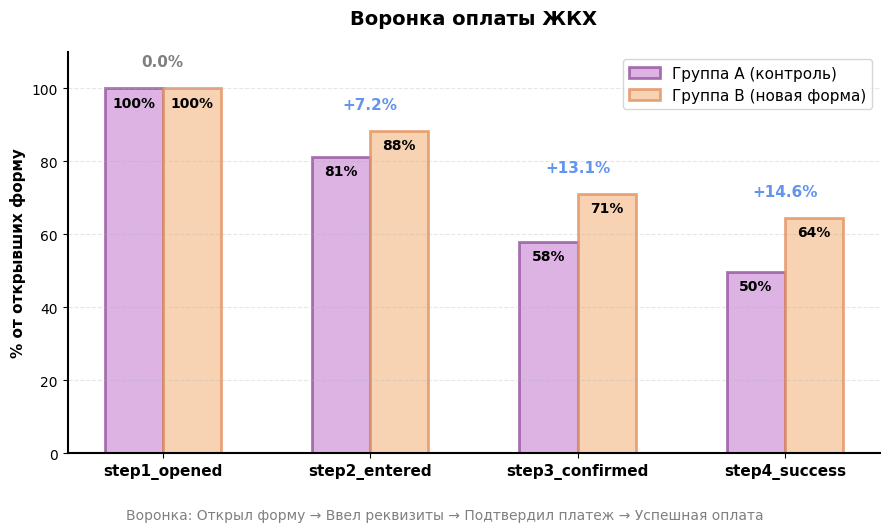

In [195]:
fig, ax = plt.subplots(figsize=(9, 5))

steps_labels = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
vals_a = funnel.loc['A', ['step1','step2','step3','step4']].values / funnel.loc['A','step1']
vals_b = funnel.loc['B', ['step1','step2','step3','step4']].values / funnel.loc['B','step1']

x = np.arange(4)
w = 0.28

bars_a = ax.bar(x - w/2, vals_a*100, w, label='Группа A (контроль)', 
                color='#D4A0DC', edgecolor='#93539D', linewidth=2, alpha=0.8)
bars_b = ax.bar(x + w/2, vals_b*100, w, label='Группа B (новая форма)', 
                color='#F5C9A0', edgecolor='#E3915F', linewidth=2, alpha=0.8)

ax.set_xticks(x)
ax.set_xticklabels(steps_labels, fontsize=11, fontweight='bold')  # Старые подписи
ax.set_ylabel('% от открывших форму', fontsize=11, fontweight='bold')
ax.set_title('Воронка оплаты ЖКХ', fontsize=14, fontweight='bold', pad=20)

ax.set_ylim(0, 110)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)
ax.yaxis.grid(True, linestyle='--', alpha=0.3)

for i, v in enumerate(vals_a*100):
    ax.text(i - w/2, v - 5, f'{v:.0f}%', ha='center', fontsize=10, fontweight='bold')
for i, v in enumerate(vals_b*100):
    ax.text(i + w/2, v - 5, f'{v:.0f}%', ha='center', fontsize=10, fontweight='bold')
    
for i in range(4):
    diff = vals_b[i] - vals_a[i]
    diff_percent = diff * 100
    y_pos = max(vals_a[i], vals_b[i]) * 100 + 6
    
    if diff > 0:
        color = 'cornflowerblue'
        sign = '+'
    elif diff < 0:
        color = 'red'
        sign = ''
    else:
        color = 'gray'
        sign = ''
    
    ax.text(i, y_pos, f'{sign}{diff_percent:.1f}%', 
            ha='center', fontsize=11, fontweight='bold', color=color)

ax.legend(loc='upper right', fontsize=11, frameon=True)

plt.figtext(0.5, -0.05, 'Воронка: Открыл форму → Ввел реквизиты → Подтвердил платеж → Успешная оплата', 
            ha='center', fontsize=10, color='gray')

plt.tight_layout()
plt.show()

Прирост у группы B увеличивается на каждом шаге воронки, а не только в точке ввода реквизитов

#### **Статистическая проверка гипотезы**

**Гипотеза:** Новая форма с автозаполнением реквизитов увеличит долю успешных оплат ЖКХ

**Ключевая метрика:** Конверсия из шага 1 в шаг 4 **на уровне пользователя** (успех/неуспех)

Используем двухвыборочный **z**-тест для пропорций.

Условия применимости теста о размере и независимости выборок выполняются на наших данных

In [220]:
def two_prop_ztest(x1, n1, x2, n2):
    p1, p2 = x1/n1, x2/n2
    p_pool = (x1+x2)/(n1+n2)
    se_pool = np.sqrt(p_pool*(1-p_pool)*(1/n1+1/n2))
    z = (p2-p1)/se_pool
    p_val = 2*(1-stats.norm.cdf(abs(z)))
    se_diff = np.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)
    diff = p2-p1
    ci = (diff-1.96*se_diff, diff+1.96*se_diff)
    return p1, p2, diff, z, p_val, ci

xA, nA = itt.loc['A','successes'], itt.loc['A','n']
xB, nB = itt.loc['B','successes'], itt.loc['B','n']
p1, p2, diff, z, pval, ci = two_prop_ztest(xA, nA, xB, nB)

print(f'p_A = {p1:.4f} ({p1:.2%})', end=', ')
print(f'p_B = {p2:.4f} ({p2:.2%})')
print(f'Разница (B - A) = {diff:.4f} = {diff*100:.2f} п.п.')
print(f'z-статистика = {z:.3f}')
print(f'p-value = {pval:.6f}')
print(f'95й доверительный интервал для разницы: [{ci[0]*100:.2f} п.п. - {ci[1]*100:.2f} п.п.]')

p_A = 0.6569 (65.69%), p_B = 0.8040 (80.40%)
Разница (B - A) = 0.1471 = 14.71 п.п.
z-статистика = 6.419
p-value = 0.000000
95й доверительный интервал для разницы: [10.28 п.п. - 19.14 п.п.]


Также можно было использовать $\chi$-квадрат тест, для дополнительной проверки:

In [199]:
table = [[xA, nA-xA], [xB, nB-xB]]
chi2b, pb, dof, exp = stats.chi2_contingency(table, correction=False)
print(f'chi2 = {chi2b:.3f}, p-value = {pb:.6f}')

chi2 = 41.202, p-value = 0.000000


Дополнительная проверка гипотезы при выборе конверсии по первой попытке:

In [215]:
xA2, nA2 = fa.loc['A','successes'], fa.loc['A','n']
xB2, nB2 = fa.loc['B','successes'], fa.loc['B','n']
p1b, p2b, diffb, zb, pvalb, cib = two_prop_ztest(xA2, nA2, xB2, nB2)
print(f'p_A = {p1b:.4}, p_B = {p2b:.4}\nРазница (B - A) = {diffb:.4f}\np-value = {pvalb:.6f}')


p_A = 0.5073, p_B = 0.6573
Разница (B - A) = 0.1500
p-value = 0.000000


Эффект получился практически одинаковым по размеру и значимости в обоих случаях

`p-value ≈ 0.0000` означает, что вероятность получить такую же или большую разницу, если бы на самом деле эффекта не было, крайне мала (стремится к 0), это показывает очень высокую статистическую значимость эффекта

#### **MDE и практическая значимость**

In [222]:
alpha = 0.05
power = 0.80
z_alpha = stats.norm.ppf(1 - alpha/2)
z_beta = stats.norm.ppf(power)
p_base = p1 
n_per_group = nA

mde = (z_alpha + z_beta) * np.sqrt(2 * p_base * (1 - p_base) / n_per_group)

print(f'MDE при alpha = 0.05 и мощности = 80%: {mde*100:.2f} п.п.')
print(f'Фактически обнаруженный эффект: {diff*100:.2f} п.п.')


MDE при alpha = 0.05 и мощности = 80%: 6.87 п.п.
Фактически обнаруженный эффект: 14.71 п.п.


Новая форма увеличивает конверсию на 14.71 п.п., что соответствует относительному приросту в **+22.4%**

Нижняя граница доверительного интервала в 1.5 раза больше, чем MDE, это говорит о том, что эффект надежно превышает минимально значимый порог и это не пограничный случай

#### **Результаты A/B теста**

| Показатель | Значение |
|--|--|
|Конверсия в группе A (контрольная группа) | `65.69%` |
|Конверсия в группе B (новая форма) | `80.40% `|
|Разница | `+ 14.71 п.п.` |
|Статистическая значимость| `p-value ≈ 0.000000`, `z = 6.42`|
|95% доверительный интервал для разницы | `[10.28 п.п. - 19.14 п.п.]`|
|MDE при $\alpha$ = 0.05 и мощности 80% | `6.87 п.п.`|

#### **Вывод**

Новая форма с автозаполнением реквизитов показывает статистически и практически значимый эффект (`p < 0.001`, прирост конверсии на `14.71 п.п.` (это очень большой эффект для платежной воронки), что соответствует росту успешных платежей на `22.4%`)

Можно **уверенно рекомендовать** запуск новой формы с автозаполнением реквизитов на всех пользователей

С точки зрения бизнеса это означает увеличение выручки без привлечения нового трафика за счет упрощения пользовательского сценария
